In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np

In [2]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

### A

In [2]:
australia_profile = pd.read_parquet("../data/by_country/Australia_macro_profile.parquet")
australia_profile

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
0,2007,NaN,NaN,NaN,NaN,NaN,NaN,78.7775,NaN,283.4875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2008,NaN,NaN,NaN,NaN,NaN,NaN,87.3575,NaN,309.1825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009,NaN,NaN,NaN,NaN,NaN,NaN,86.2500,NaN,315.9400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010,NaN,NaN,NaN,NaN,NaN,NaN,89.9575,NaN,341.5600,NaN,NaN,100.0000,NaN,NaN,NaN,NaN,NaN,NaN
4,2011,NaN,NaN,NaN,NaN,NaN,NaN,97.0800,NaN,367.2525,NaN,NaN,97.8450,NaN,NaN,NaN,NaN,NaN,NaN
5,2012,NaN,NaN,NaN,NaN,NaN,NaN,106.9800,101.025,378.9825,NaN,NaN,97.5325,NaN,NaN,NaN,NaN,NaN,NaN
6,2013,NaN,NaN,NaN,NaN,NaN,52.751667,106.8425,103.500,392.4275,NaN,NaN,103.9925,NaN,NaN,NaN,NaN,NaN,NaN
7,2014,NaN,NaN,NaN,NaN,NaN,60.172500,106.6775,106.075,403.4525,2059.295833,NaN,113.4075,NaN,NaN,NaN,NaN,NaN,NaN
8,2015,NaN,102.4,45.31,NaN,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,NaN,123.6450,NaN,NaN,21.87,NaN,5.46,NaN
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53


In [3]:
australia_profile_2015 = australia_profile[(australia_profile['Year'] >= 2015) & (australia_profile['Year'] <= 2024)].copy()
australia_profile_2016 = australia_profile[(australia_profile['Year'] >= 2016) & (australia_profile['Year'] <= 2024)].copy()

In [6]:
australia_profile_2015

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
8,2015,NaN,102.4,45.31,NaN,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,NaN,123.6450,NaN,NaN,21.87,NaN,5.46,NaN
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350,1.65,23.47,22.09,1.9,5.32,1.50
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050,1.67,24.12,23.18,1.9,5.41,1.56
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400,1.69,25.27,23.38,1.6,5.51,1.54
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525,1.62,25.39,22.56,0.8,5.38,1.57
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925,1.64,25.42,23.03,2.9,5.33,1.47
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200,1.51,27.48,23.60,6.6,5.21,1.53
16,2023,14.50,NaN,NaN,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500,1.52,27.65,NaN,5.6,NaN,1.59
17,2024,NaN,NaN,NaN,NaN,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275,NaN,25.97,NaN,3.2,NaN,NaN


In [4]:
australia_profile_2016

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350,1.65,23.47,22.09,1.9,5.32,1.50
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050,1.67,24.12,23.18,1.9,5.41,1.56
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400,1.69,25.27,23.38,1.6,5.51,1.54
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525,1.62,25.39,22.56,0.8,5.38,1.57
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925,1.64,25.42,23.03,2.9,5.33,1.47
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200,1.51,27.48,23.60,6.6,5.21,1.53
16,2023,14.50,NaN,NaN,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500,1.52,27.65,NaN,5.6,NaN,1.59
17,2024,NaN,NaN,NaN,NaN,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275,NaN,25.97,NaN,3.2,NaN,NaN


In [5]:
australia_profile_2015 = australia_profile_2015.ffill()
australia_profile_2015 = australia_profile_2015.bfill()
australia_profile_2016 = australia_profile_2016.ffill()
australia_profile_2016 = australia_profile_2016.bfill()

In [7]:
def filtrar_columnas(df):
    palabras_clave = [
        'gdp', 'urban_pop', 'gov_exp', 'priv_cred', 'investment',
        'inflation', 'labor_force', 'unemployment', 'edu_spending',
        'rule_of_law', 'govermment_effective'
    ]
    
    columnas_filtradas = [col for col in df.columns if any(palabra in col.lower() for palabra in palabras_clave)]
    return df[columnas_filtradas]

In [8]:
australia_profile_2016 = filtrar_columnas(australia_profile_2016)

In [9]:
australia_profile_2016

,labor_force,urban_pop,gov_exp,investment,gdp,priv_cred,unemployment,rule_of_law_df,inflation_df,edu_spending_df,govermment_effective_df
9,12.73,85.80,85.2900,104.4575,424.6600,2367.798333,5.713333,1.72,1.9,5.43,1.53
10,13.01,85.90,89.7925,109.4400,450.3775,2493.594167,5.606667,1.65,1.9,5.32,1.50
11,13.31,86.01,95.3525,114.2550,473.9000,2550.039167,5.306667,1.67,1.9,5.41,1.56
12,13.59,86.12,103.7050,113.9775,498.6975,2589.645000,5.165000,1.69,1.6,5.51,1.54
13,13.58,86.24,113.1950,111.7475,494.0275,2656.729167,6.441667,1.62,0.8,5.38,1.57
14,13.80,86.36,122.0550,127.3975,550.6875,2760.232500,5.138333,1.64,2.9,5.33,1.47
15,14.07,86.49,133.1300,142.0275,620.9125,2991.540000,3.725833,1.51,6.6,5.21,1.53
16,14.50,86.62,142.2425,157.1425,655.5775,3173.511667,3.686667,1.52,5.6,5.21,1.59
17,14.50,86.62,154.9175,166.4175,680.3275,3340.351667,3.686667,1.52,3.2,5.21,1.59


In [4]:
def plot_and_return_vif(df_country):
    """
    Plots a heatmap of the Variance Inflation Factor (VIF) and returns a DataFrame with VIF values.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns

    Returns:
    - vif_df: DataFrame with variables and their corresponding VIF values
    """
    # Drop 'Year' column and rows with missing values
    df_macro = df_country.drop(columns=['Year'], errors='ignore').dropna()

    # Standardize the data (optional but improves VIF stability)
    df_std = (df_macro - df_macro.mean()) / df_macro.std()

    # Compute VIF values
    vif_data = {
        'Variable': df_std.columns,
        'VIF': [variance_inflation_factor(df_std.values, i) for i in range(df_std.shape[1])]
    }
    vif_df = pd.DataFrame(vif_data).set_index('Variable')

    # Plot heatmap (diagonal matrix for visual emphasis)
    vif_matrix = np.diag(vif_df['VIF'])
    vif_heatmap_df = pd.DataFrame(vif_matrix, index=vif_df.index, columns=vif_df.index)

    plt.figure(figsize=(12, 10))
    sns.heatmap(vif_heatmap_df, annot=True, fmt=".2f", cmap="Reds", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Variance Inflation Factor (VIF) Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return vif_df

In [5]:
def plot_and_return_macro_correlation(df_country):
    """
    Plots a heatmap of the correlation matrix for macroeconomic indicators
    and returns the correlation DataFrame.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns

    Returns:
    - corr_matrix: DataFrame with correlation coefficients
    """
    # Drop 'Year' column if present
    df_macro = df_country.drop(columns=['Year'], errors='ignore')

    # Compute correlation matrix
    corr_matrix = df_macro.corr()

    # Plot heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Reds', square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return corr_matrix


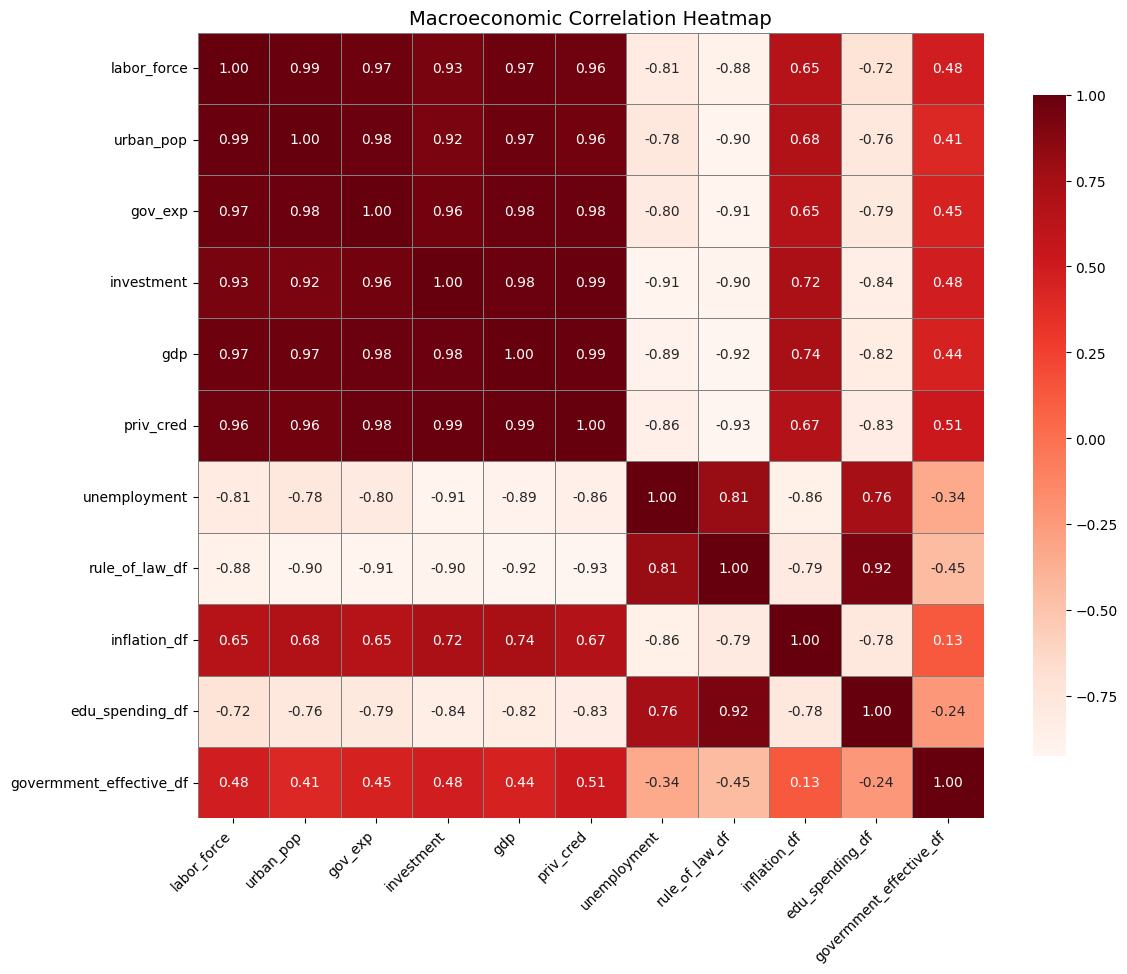

In [19]:
corr_target = plot_and_return_macro_correlation(australia_profile_2016)

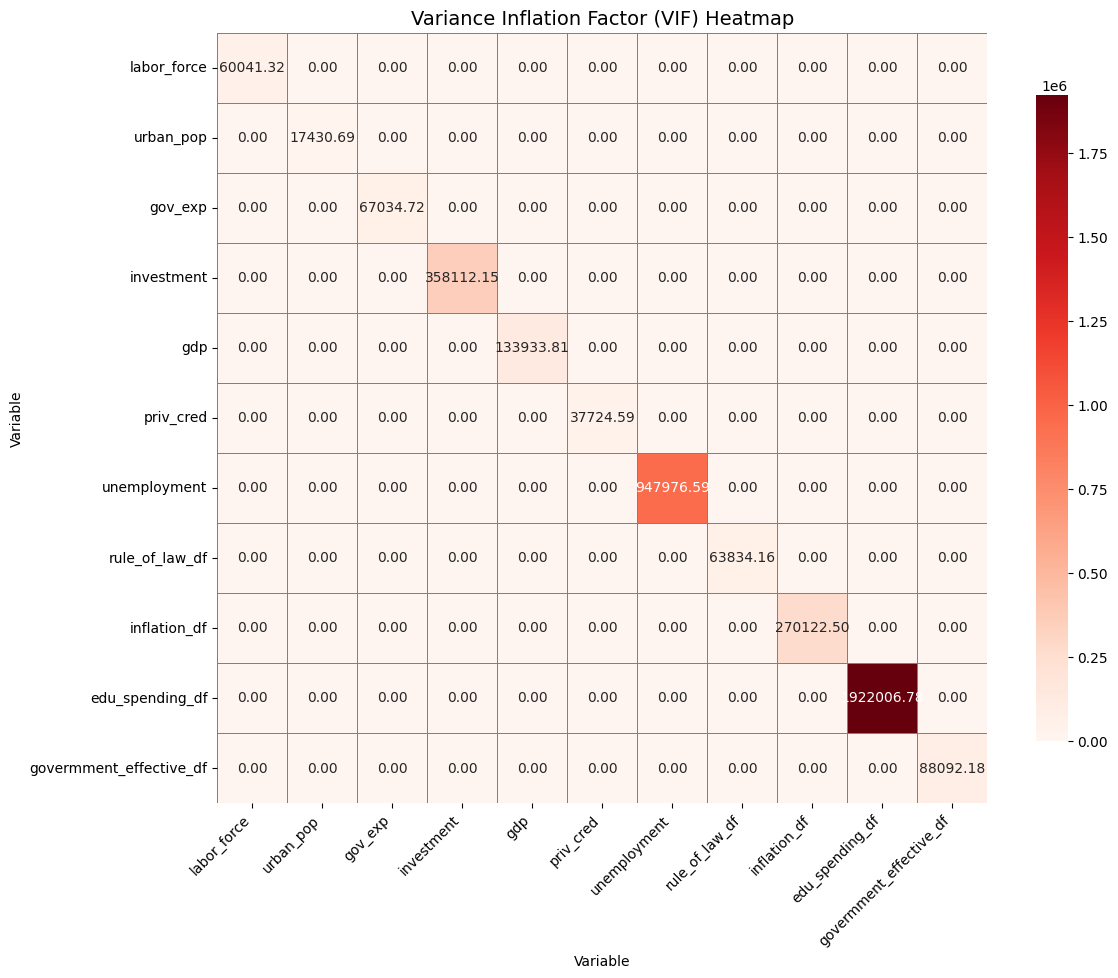

In [17]:
vif_target = plot_and_return_vif(australia_profile_2016)

In [20]:
def imprimir_variables_correlacionadas_con_vif(corr_df, vif_df, umbral_corr=0.8):
    """
    Imprime las variables más correlacionadas por encima del umbral y sus respectivos VIF.

    Parameters:
    - corr_df: DataFrame de correlaciones (output de .corr())
    - vif_df: DataFrame con VIFs (output de la función plot_and_return_vif)
    - umbral_corr: valor mínimo de correlación absoluta para considerar como alta (default: 0.8)
    """
    # Filtrar pares altamente correlacionados (sin duplicados ni diagonal)
    correlaciones_altas = []
    for i in range(len(corr_df.columns)):
        for j in range(i + 1, len(corr_df.columns)):
            var1 = corr_df.columns[i]
            var2 = corr_df.columns[j]
            corr_val = corr_df.iloc[i, j]
            if abs(corr_val) >= umbral_corr:
                correlaciones_altas.append((var1, var2, corr_val))

    # Imprimir resultados
    if correlaciones_altas:
        print(f"\n🔍 Variables con correlación |corr| ≥ {umbral_corr} y sus VIF:")
        for var1, var2, corr_val in correlaciones_altas:
            vif1 = vif_df.loc[var1, 'VIF']
            vif2 = vif_df.loc[var2, 'VIF']
            print(f"- {var1} vs {var2}: correlación = {corr_val:.2f}, VIFs = {vif1:.2f}, {vif2:.2f}")
    else:
        print(f"\n✅ No se encontraron pares con correlación |corr| ≥ {umbral_corr}.")

In [21]:
imprimir_variables_correlacionadas_con_vif(corr_target, vif_target)


🔍 Variables con correlación |corr| ≥ 0.8 y sus VIF:
- labor_force vs urban_pop: correlación = 0.99, VIFs = 60041.32, 17430.69
- labor_force vs gov_exp: correlación = 0.97, VIFs = 60041.32, 67034.72
- labor_force vs investment: correlación = 0.93, VIFs = 60041.32, 358112.15
- labor_force vs gdp: correlación = 0.97, VIFs = 60041.32, 133933.81
- labor_force vs priv_cred: correlación = 0.96, VIFs = 60041.32, 37724.59
- labor_force vs unemployment: correlación = -0.81, VIFs = 60041.32, 947976.59
- labor_force vs rule_of_law_df: correlación = -0.88, VIFs = 60041.32, 63834.16
- urban_pop vs gov_exp: correlación = 0.98, VIFs = 17430.69, 67034.72
- urban_pop vs investment: correlación = 0.92, VIFs = 17430.69, 358112.15
- urban_pop vs gdp: correlación = 0.97, VIFs = 17430.69, 133933.81
- urban_pop vs priv_cred: correlación = 0.96, VIFs = 17430.69, 37724.59
- urban_pop vs rule_of_law_df: correlación = -0.90, VIFs = 17430.69, 63834.16
- gov_exp vs investment: correlación = 0.96, VIFs = 67034.72, 

In [6]:
def resolver_multicolinealidad(df, corr_df, vif_df, umbral_corr=0.8, umbral_vif=10000, max_apariciones=5):
    """
    Elimina iterativamente variables con alta multicolinealidad según correlación y VIF.

    Parameters:
    - df: DataFrame original
    - corr_df: matriz de correlaciones
    - vif_df: tabla de VIFs
    - umbral_corr: umbral de correlación absoluta para considerar redundancia
    - umbral_vif: umbral de VIF para considerar eliminación
    - max_apariciones: número máximo de pares correlados que una variable puede tener antes de considerarse 'dominante'

    Returns:
    - df_reducido: DataFrame con variables redundantes eliminadas
    - variables_eliminadas: lista de nombres de variables eliminadas
    """
    import numpy as np
    df_reducido = df.copy()
    variables_eliminadas = []

    # Contar apariciones en pares correlados
    apariciones = {}
    pares_correlados = []

    for i in range(len(corr_df.columns)):
        for j in range(i + 1, len(corr_df.columns)):
            var1 = corr_df.columns[i]
            var2 = corr_df.columns[j]
            corr_val = corr_df.iloc[i, j]
            if abs(corr_val) >= umbral_corr:
                pares_correlados.append((var1, var2))
                apariciones[var1] = apariciones.get(var1, 0) + 1
                apariciones[var2] = apariciones.get(var2, 0) + 1

    # Iterar sobre pares y eliminar la variable con mayor VIF
    for var1, var2 in pares_correlados:
        if var1 in df_reducido.columns and var2 in df_reducido.columns:
            vif1 = vif_df.loc[var1, 'VIF']
            vif2 = vif_df.loc[var2, 'VIF']

            # Si ambas tienen VIF bajo, conservar
            if vif1 < umbral_vif and vif2 < umbral_vif:
                continue

            # Si una es dominante (aparece mucho), conservarla
            if apariciones.get(var1, 0) > max_apariciones and vif1 < vif2:
                var_a_eliminar = var2
            elif apariciones.get(var2, 0) > max_apariciones and vif2 < vif1:
                var_a_eliminar = var1
            else:
                var_a_eliminar = var1 if vif1 > vif2 else var2

            # Eliminar si no fue ya eliminada
            if var_a_eliminar in df_reducido.columns:
                df_reducido = df_reducido.drop(columns=[var_a_eliminar])
                variables_eliminadas.append(var_a_eliminar)
                print(f"🗑️ Eliminada: {var_a_eliminar} (VIF = {vif_df.loc[var_a_eliminar, 'VIF']:.2f})")

    return df_reducido, variables_eliminadas

In [24]:
df_limpio, eliminadas = resolver_multicolinealidad(australia_profile_2016, corr_target, vif_target)

🗑️ Eliminada: labor_force (VIF = 60041.32)
🗑️ Eliminada: gov_exp (VIF = 67034.72)
🗑️ Eliminada: investment (VIF = 358112.15)
🗑️ Eliminada: gdp (VIF = 133933.81)
🗑️ Eliminada: priv_cred (VIF = 37724.59)
🗑️ Eliminada: rule_of_law_df (VIF = 63834.16)
🗑️ Eliminada: unemployment (VIF = 947976.59)


In [25]:
df_limpio

,urban_pop,inflation_df,edu_spending_df,govermment_effective_df
9,85.80,1.9,5.43,1.53
10,85.90,1.9,5.32,1.50
11,86.01,1.9,5.41,1.56
12,86.12,1.6,5.51,1.54
13,86.24,0.8,5.38,1.57
14,86.36,2.9,5.33,1.47
15,86.49,6.6,5.21,1.53
16,86.62,5.6,5.21,1.59
17,86.62,3.2,5.21,1.59


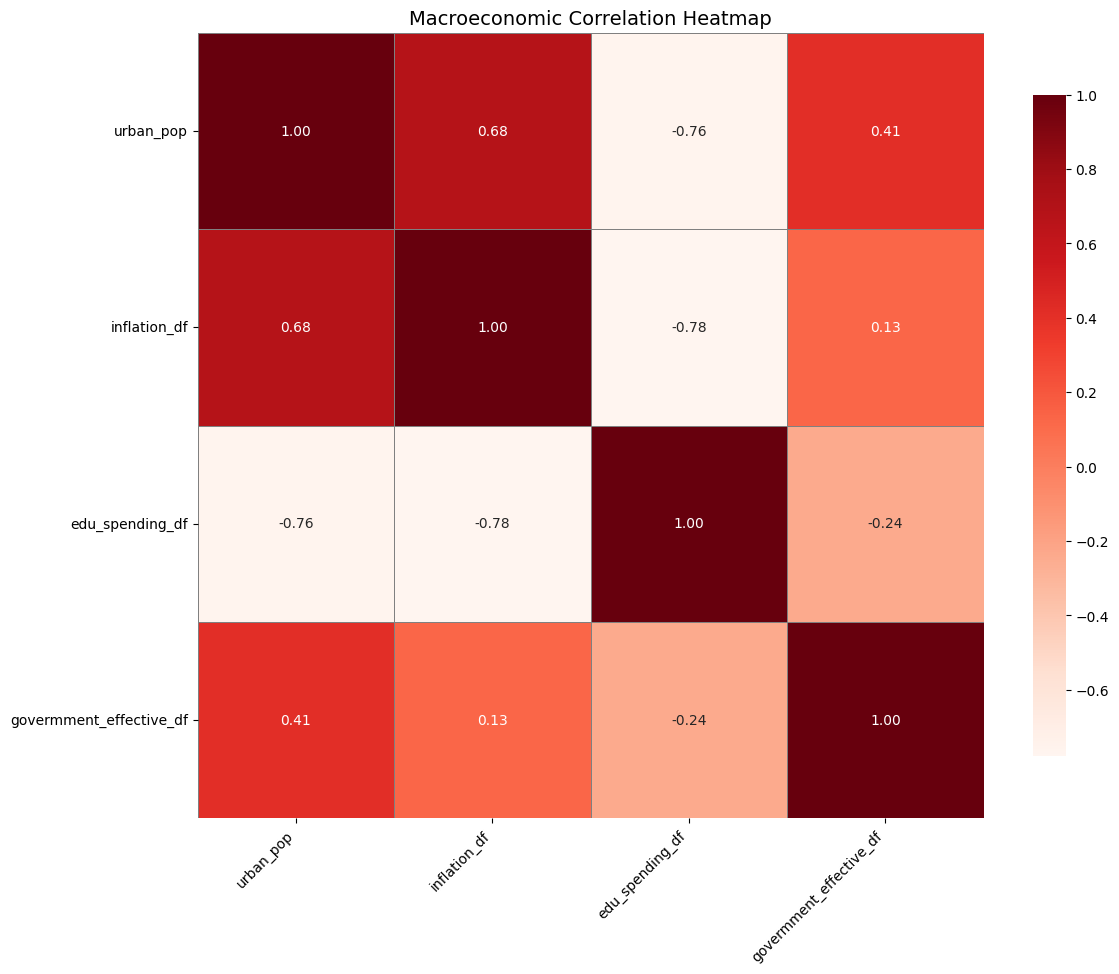

,urban_pop,inflation_df,edu_spending_df,govermment_effective_df
urban_pop,1.000000,0.682906,-0.762296,0.413016
inflation_df,0.682906,1.000000,-0.778848,0.126915
edu_spending_df,-0.762296,-0.778848,1.000000,-0.239850
govermment_effective_df,0.413016,0.126915,-0.239850,1.000000


In [26]:
plot_and_return_macro_correlation(df_limpio)

In [27]:
new_hypo = australia_profile_2016.drop(columns=['edu_spending_df'])

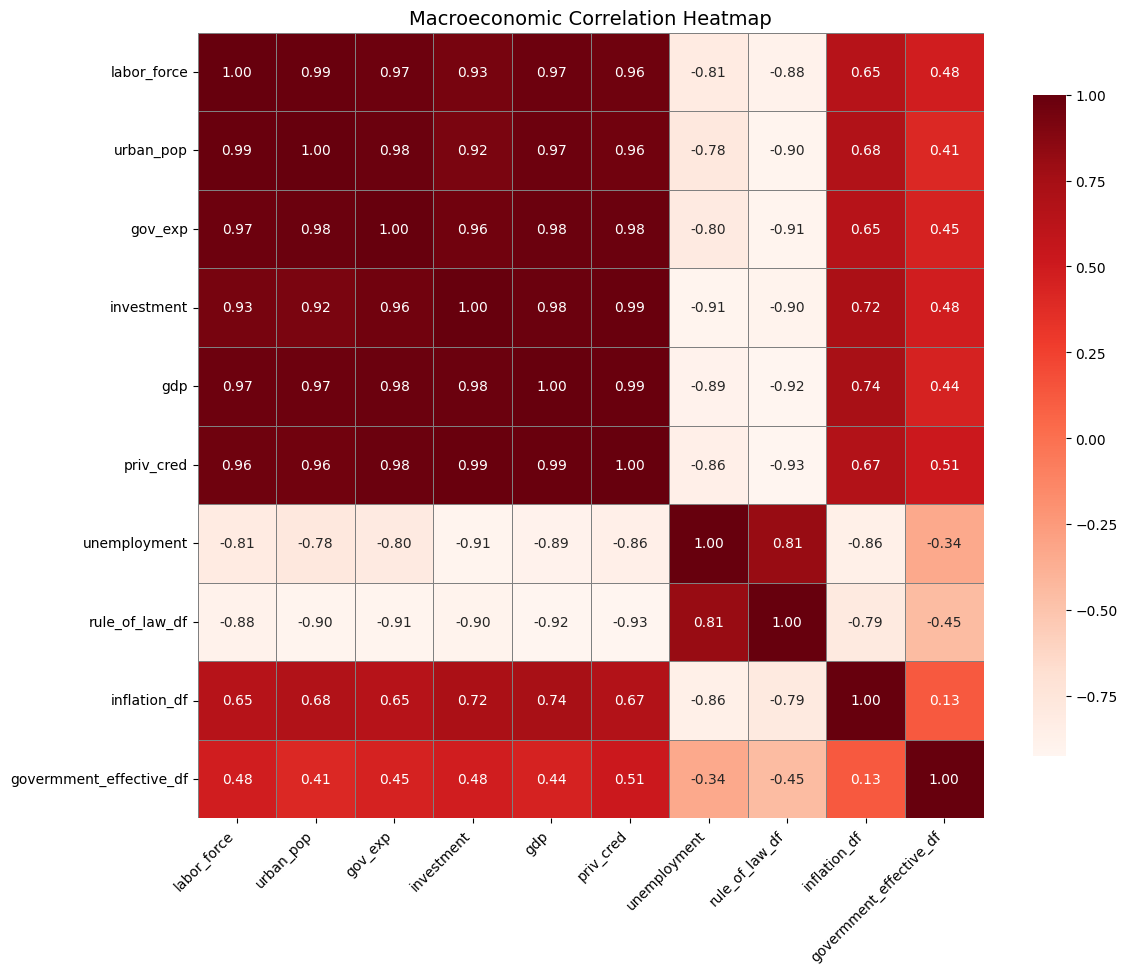

In [28]:
new_corr_target = plot_and_return_macro_correlation(new_hypo)

C:\Users\lucas\AppData\Local\pypoetry\Cache\virtualenvs\mcs-red-TMwj_-DE-py3.11\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


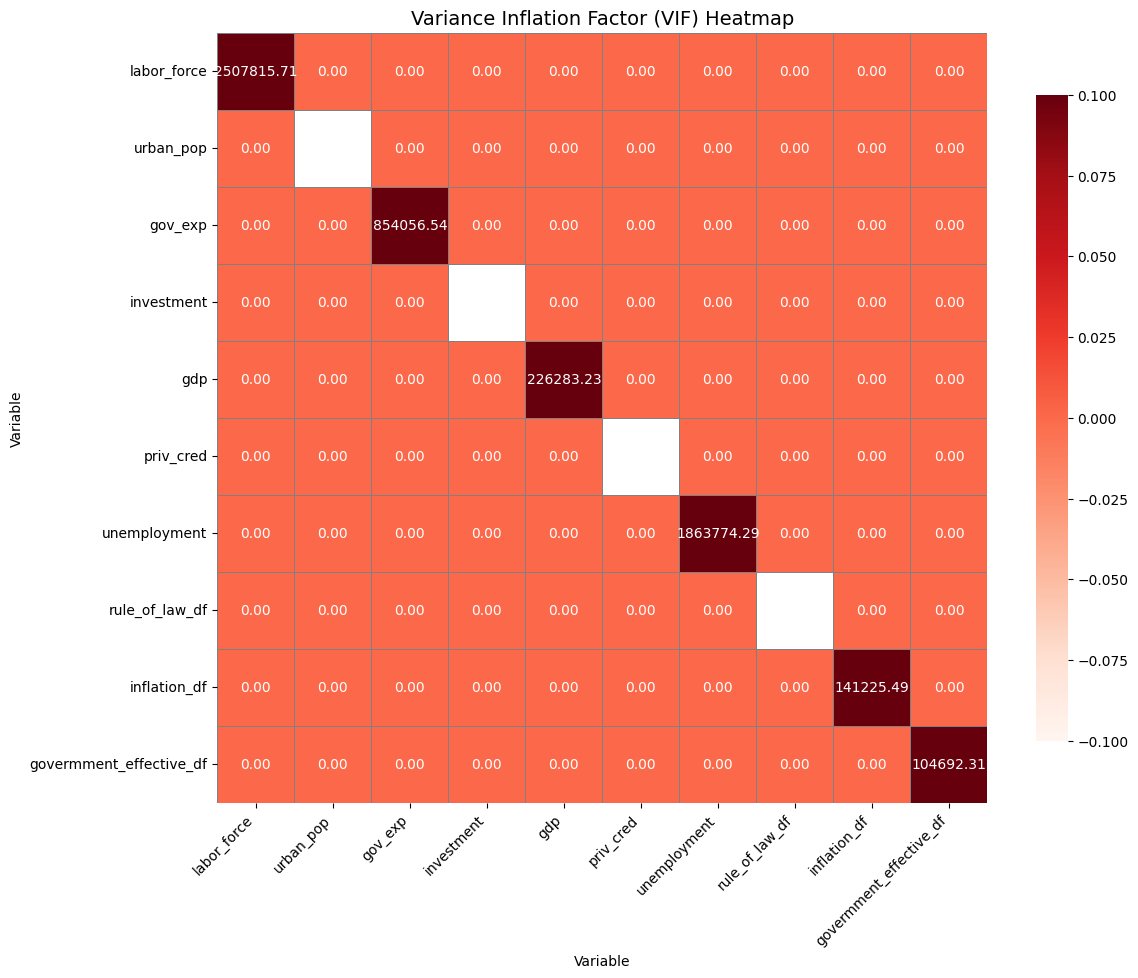

In [29]:
new_vif_target = plot_and_return_vif(new_hypo)

In [30]:
duplicadas = new_hypo.T.duplicated()
print(new_hypo.columns[duplicadas])

Index([], dtype='object')


In [31]:
print(new_hypo.std())

labor_force                  0.614166
urban_pop                    0.304590
gov_exp                     24.358157
investment                  22.549426
gdp                         93.020205
priv_cred                  329.621113
unemployment                 1.008574
rule_of_law_df               0.079547
inflation_df                 1.941649
govermment_effective_df      0.040242
dtype: float64


In [36]:
new_df_limpio1, eliminadas1 = resolver_multicolinealidad(new_hypo, new_corr_target, new_vif_target)

🗑️ Eliminada: urban_pop (VIF = inf)
🗑️ Eliminada: labor_force (VIF = 2507815.71)
🗑️ Eliminada: investment (VIF = inf)
🗑️ Eliminada: gov_exp (VIF = 854056.54)
🗑️ Eliminada: priv_cred (VIF = inf)
🗑️ Eliminada: unemployment (VIF = 1863774.29)
🗑️ Eliminada: rule_of_law_df (VIF = inf)


In [37]:
new_df_limpio

,gdp,inflation_df,govermment_effective_df
9,424.6600,1.9,1.53
10,450.3775,1.9,1.50
11,473.9000,1.9,1.56
12,498.6975,1.6,1.54
13,494.0275,0.8,1.57
14,550.6875,2.9,1.47
15,620.9125,6.6,1.53
16,655.5775,5.6,1.59
17,680.3275,3.2,1.59


In [38]:
df_sin_bajas_var = new_hypo.drop(columns=['rule_of_law_df', 'priv_cred', 'investment', 'urban_pop'])


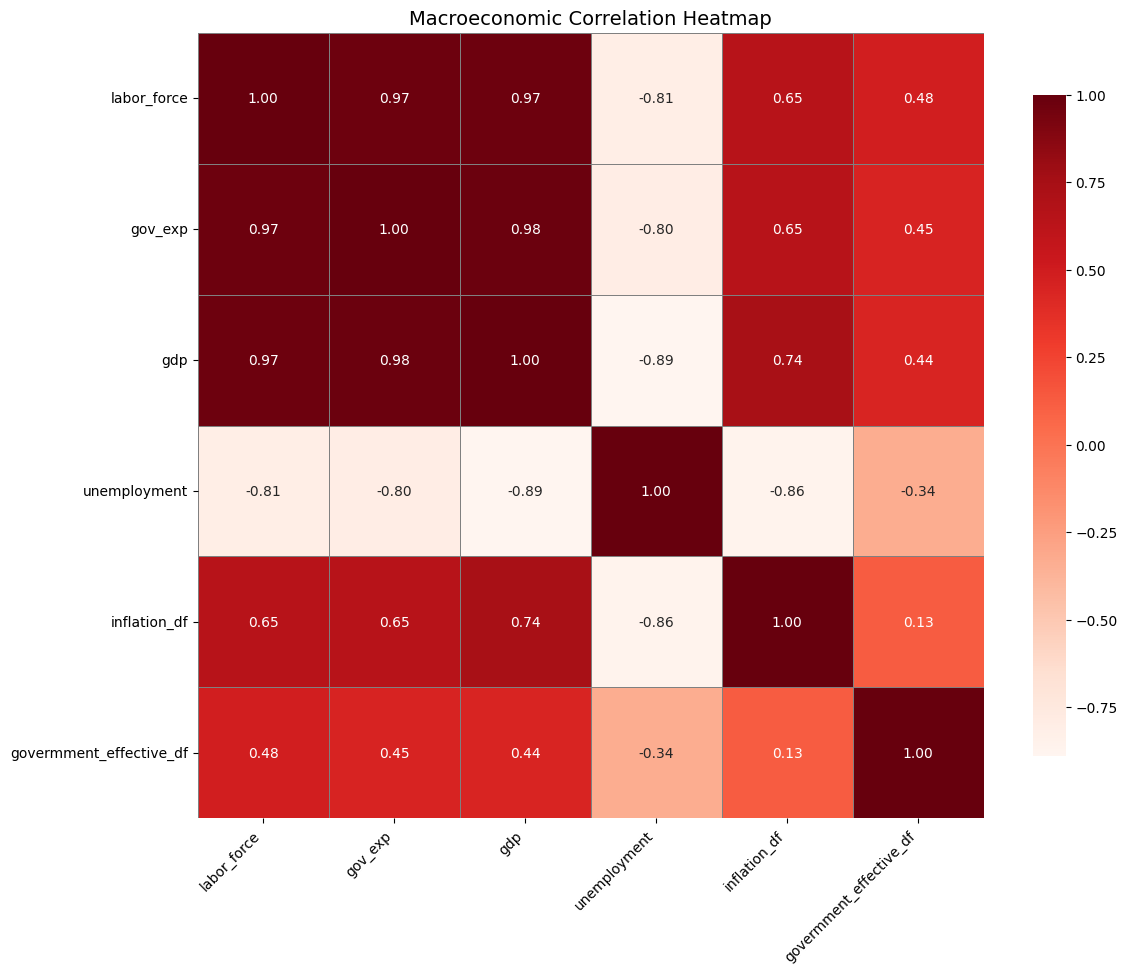

In [39]:
new_corr_target = plot_and_return_macro_correlation(df_sin_bajas_var)

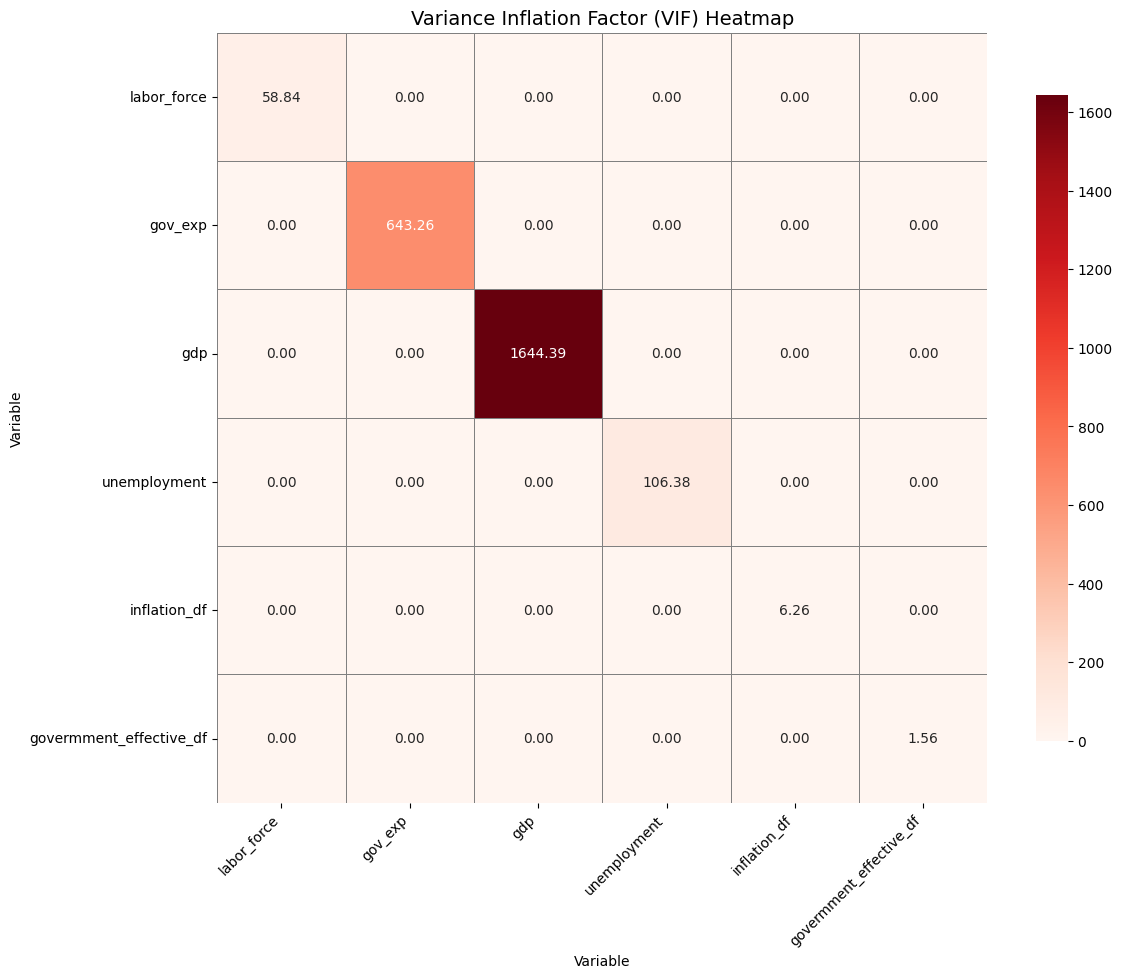

In [40]:
new_vif_target = plot_and_return_vif(df_sin_bajas_var)

In [42]:
new_df_limpio2, eliminadas3 = resolver_multicolinealidad(df_sin_bajas_var, new_corr_target, new_vif_target)

### B

In [10]:
def compute_vif(df_country):
    """
    Calcula el Factor de Inflación de la Varianza (VIF) y devuelve un DataFrame con los valores.

    Parámetros:
    - df_country: DataFrame con columna 'Year' y variables macroeconómicas

    Retorna:
    - vif_df: DataFrame con variables y sus valores de VIF
    """
    df_macro = df_country.drop(columns=['Year'], errors='ignore').dropna()
    df_std = (df_macro - df_macro.mean()) / df_macro.std()

    vif_data = {
        'Variable': df_std.columns,
        'VIF': [variance_inflation_factor(df_std.values, i) for i in range(df_std.shape[1])]
    }
    vif_df = pd.DataFrame(vif_data).set_index('Variable')
    return vif_df


In [11]:
def compute_macro_correlation(df_country):
    """
    Calcula la matriz de correlación entre indicadores macroeconómicos.

    Parámetros:
    - df_country: DataFrame con columna 'Year' y variables macroeconómicas

    Retorna:
    - corr_matrix: DataFrame con coeficientes de correlación
    """
    df_macro = df_country.drop(columns=['Year'], errors='ignore')
    corr_matrix = df_macro.corr()
    return corr_matrix

In [3]:
macro = pd.read_parquet("../data/one_point_countries_winsorized.parquet")
macro.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


In [8]:
macro_input = macro.select_dtypes(include='number')

In [12]:
corr_target = compute_macro_correlation(macro_input)

In [13]:
vif_target = compute_vif(macro_input)

C:\Users\lucas\AppData\Local\pypoetry\Cache\virtualenvs\mcs-red-TMwj_-DE-py3.11\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [14]:
df_limpio, eliminadas = resolver_multicolinealidad(macro_input, corr_target, vif_target)

🗑️ Eliminada: labor_force_median (VIF = inf)
🗑️ Eliminada: labor_force_std (VIF = inf)
🗑️ Eliminada: labor_force_min (VIF = inf)
🗑️ Eliminada: labor_force_max (VIF = inf)
🗑️ Eliminada: labor_force_last (VIF = inf)
🗑️ Eliminada: livestock_prod_median (VIF = inf)
🗑️ Eliminada: livestock_prod_max (VIF = inf)
🗑️ Eliminada: livestock_prod_last (VIF = inf)
🗑️ Eliminada: livestock_prod_growth (VIF = inf)
🗑️ Eliminada: livestock_prod_trend (VIF = inf)
🗑️ Eliminada: livestock_prod_cv (VIF = inf)
🗑️ Eliminada: urban_pop_median (VIF = inf)
🗑️ Eliminada: urban_pop_min (VIF = inf)
🗑️ Eliminada: urban_pop_max (VIF = inf)
🗑️ Eliminada: urban_pop_last (VIF = inf)
🗑️ Eliminada: gov_exp_median (VIF = inf)
🗑️ Eliminada: gov_exp_std (VIF = inf)
🗑️ Eliminada: gov_exp_min (VIF = inf)
🗑️ Eliminada: gov_exp_max (VIF = inf)
🗑️ Eliminada: gov_exp_last (VIF = inf)
🗑️ Eliminada: gov_exp_trend (VIF = inf)
🗑️ Eliminada: investment_mean (VIF = inf)
🗑️ Eliminada: investment_median (VIF = inf)
🗑️ Eliminada: investment

In [15]:
df_limpio

,labor_force_mean,livestock_prod_mean,livestock_prod_std,livestock_prod_min,urban_pop_mean,gov_exp_mean,gov_exp_cv,reserves_mean,reserves_cv,investment_cv,...,inflation__growth,inflation__skew,edu_spending__growth,edu_spending__skew,edu_spending__kurtosis,govermment_effective__cv,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,4.582413,1.820075,4.541165,4.456624,4.727279,0.195843,4.319984,0.133817,0.156194,...,-0.180908,-0.292617,-0.027544,-0.495494,-0.667223,0.138675,-0.183282,-0.557676,0.418830,0.517477
1,1.736775,4.614130,1.027869,4.606170,4.128134,3.082838,0.135154,3.253361,0.161904,0.129163,...,-0.365941,0.208691,-0.608596,-0.898845,-0.712542,0.138675,-0.219351,-0.255483,0.418830,-0.060887
2,1.825355,4.636378,1.027869,4.606170,4.473933,3.409761,0.133181,3.394961,0.213816,0.138859,...,-0.307831,0.842201,0.201990,0.929855,0.516924,0.138675,-0.262785,0.825197,-0.006636,-0.915149
3,3.719821,4.672829,1.646041,4.603168,4.465115,5.994841,0.187350,5.892785,0.110773,0.241721,...,-0.418923,0.211311,-0.552472,-0.241833,-0.753368,0.138675,-0.126735,0.825197,-0.714821,-0.915149
4,1.448095,4.582413,1.688591,4.541165,4.324358,2.358375,0.229568,4.022525,0.200555,0.230937,...,-0.564481,0.842201,0.790948,-0.898845,-0.085581,0.138675,-0.268474,-0.822060,0.057350,-0.412401
5,3.082552,4.709440,2.044840,4.595120,4.401363,4.862895,0.146059,4.550732,0.140739,0.139290,...,-0.293304,0.305038,-0.610101,-0.898845,-0.631834,0.138675,-0.227721,0.686410,-0.417763,-0.729173
6,2.328545,4.629277,1.343487,4.567468,4.473933,6.538843,0.216409,3.735634,0.110773,0.210785,...,-0.015964,0.528445,0.449749,-0.129588,-0.753368,0.138675,-0.229355,-0.822060,0.317864,-0.512542
7,3.263926,4.634729,2.047482,4.541165,4.397494,6.538843,0.218207,3.994113,0.110773,0.147894,...,-0.272020,-0.199177,0.138728,0.929855,0.516924,0.138675,-0.268474,0.825197,-0.709835,0.811769
8,1.351703,4.614724,1.427140,4.567468,4.128134,2.358375,0.198336,2.771734,0.272409,0.248974,...,0.098935,0.311279,-0.839631,0.929855,0.062705,0.138675,-0.126735,0.825197,0.258261,0.840380
9,1.351703,4.709440,2.047482,4.601162,4.202885,2.358375,0.229568,2.288579,0.272409,0.248974,...,0.133800,0.842201,-0.839631,0.746021,-0.167610,0.138675,-0.248609,-0.118785,-0.714821,-0.579984


In [16]:
df_limpio.columns

Index(['labor_force_mean', 'livestock_prod_mean', 'livestock_prod_std',
       'livestock_prod_min', 'urban_pop_mean', 'gov_exp_mean', 'gov_exp_cv',
       'reserves_mean', 'reserves_cv', 'investment_cv', 'cpi_mean', 'cpi_std',
       'cpi_min', 'priv_cred_cv', 'unemployment_mean', 'unemployment_std',
       'rule_of_law__std', 'share_of_industry__std', 'share_of_industry__max',
       'tax_revenue__std', 'tax_revenue__cv', 'inflation__median',
       'inflation__std', 'inflation__cv', 'inflation__last',
       'edu_spending__mean', 'edu_spending__std', 'govermment_effective__std',
       'labor_force_cv', 'labor_force_skew', 'labor_force_kurtosis',
       'labor_force_trend', 'livestock_prod_skew', 'livestock_prod_kurtosis',
       'agr_land_mean', 'agr_land_std', 'agr_land_growth', 'agr_land_skew',
       'agr_land_kurtosis', 'urban_pop_std', 'urban_pop_skew',
       'urban_pop_kurtosis', 'gov_exp_skew', 'gov_exp_kurtosis',
       'reserves_skew', 'reserves_kurtosis', 'investment_ske

In [17]:
df_limpio.shape

(53, 82)

In [18]:
macro.shape

(53, 189)

In [19]:
df_limpio['Country'] = macro['Country']

In [20]:
df_limpio.shape

(53, 83)

In [21]:
df_limpio

,labor_force_mean,livestock_prod_mean,livestock_prod_std,livestock_prod_min,urban_pop_mean,gov_exp_mean,gov_exp_cv,reserves_mean,reserves_cv,investment_cv,...,inflation__skew,edu_spending__growth,edu_spending__skew,edu_spending__kurtosis,govermment_effective__cv,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,Country
0,2.679788,4.582413,1.820075,4.541165,4.456624,4.727279,0.195843,4.319984,0.133817,0.156194,...,-0.292617,-0.027544,-0.495494,-0.667223,0.138675,-0.183282,-0.557676,0.418830,0.517477,Australia
1,1.736775,4.614130,1.027869,4.606170,4.128134,3.082838,0.135154,3.253361,0.161904,0.129163,...,0.208691,-0.608596,-0.898845,-0.712542,0.138675,-0.219351,-0.255483,0.418830,-0.060887,Austria
2,1.825355,4.636378,1.027869,4.606170,4.473933,3.409761,0.133181,3.394961,0.213816,0.138859,...,0.842201,0.201990,0.929855,0.516924,0.138675,-0.262785,0.825197,-0.006636,-0.915149,Belgium
3,3.719821,4.672829,1.646041,4.603168,4.465115,5.994841,0.187350,5.892785,0.110773,0.241721,...,0.211311,-0.552472,-0.241833,-0.753368,0.138675,-0.126735,0.825197,-0.714821,-0.915149,Brazil
4,1.448095,4.582413,1.688591,4.541165,4.324358,2.358375,0.229568,4.022525,0.200555,0.230937,...,0.842201,0.790948,-0.898845,-0.085581,0.138675,-0.268474,-0.822060,0.057350,-0.412401,Bulgaria
5,3.082552,4.709440,2.044840,4.595120,4.401363,4.862895,0.146059,4.550732,0.140739,0.139290,...,0.305038,-0.610101,-0.898845,-0.631834,0.138675,-0.227721,0.686410,-0.417763,-0.729173,Canada
6,2.328545,4.629277,1.343487,4.567468,4.473933,6.538843,0.216409,3.735634,0.110773,0.210785,...,0.528445,0.449749,-0.129588,-0.753368,0.138675,-0.229355,-0.822060,0.317864,-0.512542,Chile
7,3.263926,4.634729,2.047482,4.541165,4.397494,6.538843,0.218207,3.994113,0.110773,0.147894,...,-0.199177,0.138728,0.929855,0.516924,0.138675,-0.268474,0.825197,-0.709835,0.811769,Colombia
8,1.351703,4.614724,1.427140,4.567468,4.128134,2.358375,0.198336,2.771734,0.272409,0.248974,...,0.311279,-0.839631,0.929855,0.062705,0.138675,-0.126735,0.825197,0.258261,0.840380,Croatia
9,1.351703,4.709440,2.047482,4.601162,4.202885,2.358375,0.229568,2.288579,0.272409,0.248974,...,0.842201,-0.839631,0.746021,-0.167610,0.138675,-0.248609,-0.118785,-0.714821,-0.579984,Cyprus


In [22]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [23]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [24]:
df_limpio = remove_rows_by_countries(df_limpio, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


In [25]:
df_limpio['Country'] = df_limpio['Country'].replace('Czech','Czech Republic')

In [26]:
df_limpio.to_parquet('../data/one_point_win_no_multicollinearity.parquet')